# 03. NCM622 코인셀 불량 원인 분석 (4M · 5-Why · 특성요인도)
`02_전처리_분석_문제해결.ipynb`에서 찾아낸 불량 6종이 **왜 생기는지**를 정리합니다. DMAIC의 **Analyze(원인 분석)** 를 보강하는 노트북입니다.

### 먼저 짚어 둘 점
1. **불량 1건은 실제 사례입니다.** 초기 양극 샘플1이 이론 용량의 약 50%에 그쳤고, 셀을 해체해 비교한 뒤 **슬러리 점도(바인더 과다 유입)와 교반 부족**이 원인임을 확인했습니다(**0절**). 반면 `02_전처리_분석_문제해결.ipynb`의 불량 6종은 정상 셀 데이터에 불량을 주입해 만든 **불량 시나리오 데이터**이며, 그 원인(1~5절)은 **문헌과 공정 지식에 근거한 가설**입니다. 확인 방법은 6절의 검증 계획(DOE)입니다.
2. 부품규격 파일의 실제 측정값은 **5절**에서 점검합니다. 슬러리 점도는 수치 기록 없이 관찰 결과만 있습니다.
3. 불량 6종은 원인의 성격이 둘로 나뉩니다.

| 구분 | 불량 | 원인이 있는 곳 |
|---|---|---|
| **측정계 불량** | 데이터 누락, 센서 고착, 센서 스파이크, 용량 글리치 | 지그/프로브, 케이블, 사이클러(셀 자체는 정상) |
| **셀 불량** | 내부 단락 의심 | 극판 이물·버, 슬러리 분산·점도, 조립 |
| **셀 또는 설비** | 과전압 | 충전기 상한 설정·교정, (보조적으로) 셀 저항 증가 |

4. 이 셀의 양극은 **NCM622**(2.8~4.2 V)입니다. 참고한 문헌 중 일부는 Ni 함량이 더 높은 NMC811 대상이라, 같은 현상이 622에서는 더 약하게 나타날 수 있습니다.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

from pathlib import Path

# 저장소 루트에서 실행하든 notebooks/ 폴더에서 실행하든 동작
DATA_DIR = next(p for p in (Path("data"), Path("../data")) if p.exists())
OUT_DIR = DATA_DIR.parent / "outputs"          # 생성되는 결과 파일 (git에는 올리지 않음)
IMG_DIR = DATA_DIR.parent / "images"
OUT_DIR.mkdir(exist_ok=True)
IMG_DIR.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', None)


def show(df, title=None):
    """긴 한글 문장이 잘리지 않게 왼쪽 정렬로 표시"""
    if title:
        print(f"\n■ {title}")
    css = "<style>.rca td,.rca th{text-align:left !important;vertical-align:top;white-space:pre-wrap}</style>"
    display(HTML(css + "<div class='rca'>" + df.to_html(escape=True) + "</div>"))

## 0. 실제 불량 사례와 확인된 원인
작업자가 실험으로 확인한 내용(**작업자 확인**)과, 설계·측정 파일·충방전 데이터로 뒷받침되는 수치(**측정 파일**, **충방전 데이터로 확인**)를 구분해 정리했습니다.


■ 실제 불량 사례 요약


,내용,근거
단계,,
불량 발생,초기 양극 샘플1(교반 1회): 이론 용량 대비 약 50% 수준의 용량 저하,작업자 확인
해체 관찰,"슬러리 점도 차이가 극명, 전극 표면 균일성 저하, 코팅이 매우 얇아 집전체가 비쳐 보임",작업자 확인
확인된 원인,슬러리 점도 이상(바인더 과다 유입) + 교반 부족(1회),작업자 확인
개선 조치,"교반을 2회로 변경 (1회 = 5분 교반 + 1분 휴지를 5번 반복, 이를 2번 수행) 후 추가 샘플(샘플2) 제작",작업자 확인
개선 결과,샘플2 정상 충방전: 충전 1.197 mAh / 설계 1.237 mAh = 96.8%,충방전 데이터로 확인
측정값 뒷받침,양극 질량 샘플1 3.57 mg → 샘플2 8.53 mg (샘플1은 샘플2의 42%). 샘플1 코팅이 얇았다는 해체 관찰과 일치,측정 파일


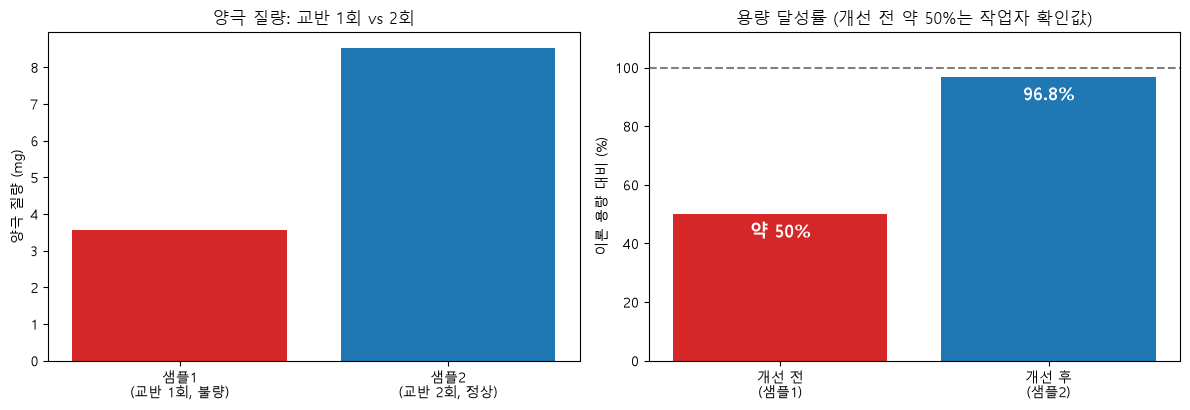

In [2]:
import openpyxl

PARTS, CELL_FILE, OWNER = DATA_DIR / "전지설계 기말과제1 부품규격.xlsx", DATA_DIR / "전압 및 용량 데이터.xlsx", "학생5"


def cells(ws, rng):
    return np.array([c.value for row in ws[rng] for c in row], dtype=float)


def cv(x):
    return np.std(x, ddof=1) / np.mean(x) * 100


wb = openpyxl.load_workbook(PARTS, data_only=True)
ws = wb['질량 및 용량, 전류']
names = [c.value for row in ws['A2:A6'] for c in row]
m1, m2 = cells(ws, 'B2:B6') * 1000, cells(ws, 'E2:E6')          # sample1 (g→mg), sample2 (mg)
k = names.index(OWNER)
m_bad, m_ok = m1[k], m2[k]

Qc = pd.read_excel(CELL_FILE)['누적 용량_d(Ah/cm2)'].to_numpy()
imx = int(np.argmax(Qc))
cap_design = 145 * m_ok * 1e-3                       # 실용량 145 mAh/g × 양극 질량 (mAh)
cap_meas = (Qc[imx] - Qc[0]) * 1000                  # 실측 충전 용량 (mAh)
ach_ok = cap_meas / cap_design * 100
ACH_BAD = 50                                         # 샘플1 용량 달성률 (작업자 확인: 이론 용량 대비 약 50%)

case = pd.DataFrame([
    ['불량 발생', '초기 양극 샘플1(교반 1회): 이론 용량 대비 약 50% 수준의 용량 저하', '작업자 확인'],
    ['해체 관찰', '슬러리 점도 차이가 극명, 전극 표면 균일성 저하, 코팅이 매우 얇아 집전체가 비쳐 보임', '작업자 확인'],
    ['확인된 원인', '슬러리 점도 이상(바인더 과다 유입) + 교반 부족(1회)', '작업자 확인'],
    ['개선 조치', '교반을 2회로 변경 (1회 = 5분 교반 + 1분 휴지를 5번 반복, 이를 2번 수행) 후 추가 샘플(샘플2) 제작', '작업자 확인'],
    ['개선 결과', f"샘플2 정상 충방전: 충전 {cap_meas:.3f} mAh / 설계 {cap_design:.3f} mAh = {ach_ok:.1f}%", '충방전 데이터로 확인'],
    ['측정값 뒷받침', f"양극 질량 샘플1 {m_bad:.2f} mg → 샘플2 {m_ok:.2f} mg (샘플1은 샘플2의 {m_bad / m_ok * 100:.0f}%). 샘플1 코팅이 얇았다는 해체 관찰과 일치", '측정 파일'],
], columns=['단계', '내용', '근거']).set_index('단계')
show(case, '실제 불량 사례 요약')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(['샘플1\n(교반 1회, 불량)', '샘플2\n(교반 2회, 정상)'], [m_bad, m_ok], color=['tab:red', 'tab:blue'])
axes[0].set_ylabel('양극 질량 (mg)'); axes[0].set_title('양극 질량: 교반 1회 vs 2회')
axes[1].bar(['개선 전\n(샘플1)', '개선 후\n(샘플2)'], [ACH_BAD, ach_ok], color=['tab:red', 'tab:blue'])
axes[1].axhline(100, color='gray', ls='--'); axes[1].set_ylim(0, 112); axes[1].set_ylabel('이론 용량 대비 (%)')
axes[1].set_title('용량 달성률 (개선 전 약 50%는 작업자 확인값)')
for i, v in enumerate([ACH_BAD, ach_ok]):
    axes[1].text(i, v - 8, f"약 {v:.0f}%" if i == 0 else f"{v:.1f}%", ha='center', color='white', fontweight='bold', fontsize=13)
plt.tight_layout(); plt.show()

> **한계**: 교반 1회 vs 2회는 **각 1개 샘플**의 비교이고, 점도는 수치 없이 해체 시 관찰한 내용입니다. "교반 2회에서 정상 셀이 나왔다"는 **사례 확인**이며 통계적 검증은 아닙니다. 6절에서 반복 실험 계획을 제시합니다.

## 1. 4M 분석 (Man · Machine · Material · Method)
NCM622 양극 슬러리부터 코인셀 조립·측정까지 단계별로 불량 원인을 4M으로 분류했습니다.
근거 번호 `[n]`은 맨 아래 참고 문헌입니다.

In [3]:
rows = [
    # (4M, 공정 단계, 원인 항목, 영향 메커니즘, 관련 불량, 근거)
    ('Material', '양극 슬러리', 'NCM622 양극의 잔류 리튬(LiOH·Li2O)·수분',
     '잔류 Li2O가 PVDF 바인더를 분해(LiF 생성)하고 슬러리 겔화를 일으킴 → 점도 변동, 코팅 불균일, 접착력 저하 (문헌은 Ni 함량이 더 높은 NMC811 대상이라 622에서는 영향이 더 작을 수 있음)', '내부 단락 의심, 과전압', '[1][5][6]'),
    ('Material', '양극 슬러리', 'PVDF 용해 상태 · NMP 수분',
     'PVDF 불완전 용해(겔 분율)로 PVDF가 몰린 부분 생김, 도전재 분산이 수분 등 통제 안 되는 요인에 민감', '내부 단락 의심, 과전압', '[2]'),
    ('Material', '양극 슬러리', '도전재(Super P) 응집',
     '응집체가 전극 두께·저항을 국부적으로 불균일하게 만들어 전류가 몰림', '내부 단락 의심, 과전압', '[2][3][4]'),
    ('Material', '극판·부품', 'Al박·분리막·극판의 금속 이물, 절단 버(burr)',
     '이물이 전극 사이에 끼고 충방전 중 팽창으로 분리막을 압박·관통하거나, 금속이 용해·재석출되어 전극을 잇는 다리를 만듦', '내부 단락 의심', '[7][8][13]'),
    ('Method', '양극 슬러리', '★ 고형분·점도 설정 / 바인더 투입량 (실험 확인)',
     '점도가 낮으면 흘러내림, 높으면 줄무늬·덩어리. 바인더 과다는 저항 증가, 도전재 과소는 전도망 단절. 실제 사례에서 바인더가 과다 유입되어 점도가 달라졌고 코팅이 얇고 불균일했음', '용량 저하(실제), 내부 단락 의심, 과전압', '실험 + [2][3]'),
    ('Method', '양극 슬러리', '★ 교반 횟수 · 순서 · 시간 · 전단 세기 (실험 확인)',
     '교반이 부족하면 응집체 잔존·혼합 불균일, 과하면 활물질 손상과 치밀한 응집층 형성. 실제 사례에서 교반을 1회 → 2회로 늘리자 정상 셀이 나옴', '용량 저하(실제), 내부 단락 의심, 과전압', '실험 + [3][4][10]'),
    ('Method', '코팅·건조·압연', '건조 온도·속도, 압연 밀도, 로딩량',
     '건조 불균일은 바인더 편석과 박리, 압연 과다는 균열·분리막 압박 증가', '내부 단락 의심', '공정 지식'),
    ('Method', '코인셀 조립', '크림핑 압력·유지 시간, 전해액량, 음극/양극 면적비',
     '압력·전해액량 편차는 셀마다 내부 압력과 접촉 상태를 달리해 재현성을 떨어뜨림. 면적비를 1.12~1.15로 두면 정렬 오차를 흡수', '내부 단락 의심, 센서 스파이크', '[11][12][13]'),
    ('Machine', '양극 슬러리', '믹서·분산기 마모',
     '교반 날·용기 마모로 Fe 등 금속 입자가 슬러리에 혼입', '내부 단락 의심', '[7]'),
    ('Machine', '코팅·절단', '코터 갭·슬릿 편차, 펀칭 금형 마모',
     '도포 두께 편차, 금형 마모로 극판 가장자리 버 발생', '내부 단락 의심', '[7][13]'),
    ('Machine', '조립·측정', '크림퍼 압력 편차, 사이클러 전압 상한 설정·교정, 통신/샘플링',
     '상한 설정 오류·교정 편차는 과전압, 통신·샘플링 오류는 누락·고착·글리치로 나타남', '과전압, 데이터 누락, 센서 고착, 용량 글리치', '[11] + 설비 지식'),
    ('Man', '코인셀 조립', '분리막 정렬(편심), 전해액 주입량 편차, 핀셋·장갑 오염',
     '정렬이 틀어지면 양극과 음극이 직접 접촉할 위험, 오염은 이물 혼입', '내부 단락 의심', '[12][13]'),
    ('Man', '극판 준비', '극판 무게·두께·버 미확인, 부품 건조 누락',
     '불량 극판이 조립 공정으로 넘어가고, 잔류 수분이 이상 거동을 유발', '내부 단락 의심', '[13]'),
    ('Man', '측정', '지그 체결·접촉 상태 확인 소홀',
     '접촉 저항 변동이 전압 노이즈·끊김으로 기록됨', '센서 스파이크, 센서 고착, 데이터 누락', '설비 지식'),
]
fourM = pd.DataFrame(rows, columns=['4M', '공정 단계', '원인 항목', '영향 메커니즘', '관련 불량', '근거'])
show(fourM, '4M 원인 정리표')


■ 4M 원인 정리표


,4M,공정 단계,원인 항목,영향 메커니즘,관련 불량,근거
0,Material,양극 슬러리,NCM622 양극의 잔류 리튬(LiOH·Li2O)·수분,"잔류 Li2O가 PVDF 바인더를 분해(LiF 생성)하고 슬러리 겔화를 일으킴 → 점도 변동, 코팅 불균일, 접착력 저하 (문헌은 Ni 함량이 더 높은 NMC811 대상이라 622에서는 영향이 더 작을 수 있음)","내부 단락 의심, 과전압",[1][5][6]
1,Material,양극 슬러리,PVDF 용해 상태 · NMP 수분,"PVDF 불완전 용해(겔 분율)로 PVDF가 몰린 부분 생김, 도전재 분산이 수분 등 통제 안 되는 요인에 민감","내부 단락 의심, 과전압",[2]
2,Material,양극 슬러리,도전재(Super P) 응집,응집체가 전극 두께·저항을 국부적으로 불균일하게 만들어 전류가 몰림,"내부 단락 의심, 과전압",[2][3][4]
3,Material,극판·부품,"Al박·분리막·극판의 금속 이물, 절단 버(burr)","이물이 전극 사이에 끼고 충방전 중 팽창으로 분리막을 압박·관통하거나, 금속이 용해·재석출되어 전극을 잇는 다리를 만듦",내부 단락 의심,[7][8][13]
4,Method,양극 슬러리,★ 고형분·점도 설정 / 바인더 투입량 (실험 확인),"점도가 낮으면 흘러내림, 높으면 줄무늬·덩어리. 바인더 과다는 저항 증가, 도전재 과소는 전도망 단절. 실제 사례에서 바인더가 과다 유입되어 점도가 달라졌고 코팅이 얇고 불균일했음","용량 저하(실제), 내부 단락 의심, 과전압",실험 + [2][3]
5,Method,양극 슬러리,★ 교반 횟수 · 순서 · 시간 · 전단 세기 (실험 확인),"교반이 부족하면 응집체 잔존·혼합 불균일, 과하면 활물질 손상과 치밀한 응집층 형성. 실제 사례에서 교반을 1회 → 2회로 늘리자 정상 셀이 나옴","용량 저하(실제), 내부 단락 의심, 과전압",실험 + [3][4][10]
6,Method,코팅·건조·압연,"건조 온도·속도, 압연 밀도, 로딩량","건조 불균일은 바인더 편석과 박리, 압연 과다는 균열·분리막 압박 증가",내부 단락 의심,공정 지식
7,Method,코인셀 조립,"크림핑 압력·유지 시간, 전해액량, 음극/양극 면적비",압력·전해액량 편차는 셀마다 내부 압력과 접촉 상태를 달리해 재현성을 떨어뜨림. 면적비를 1.12~1.15로 두면 정렬 오차를 흡수,"내부 단락 의심, 센서 스파이크",[11][12][13]
8,Machine,양극 슬러리,믹서·분산기 마모,교반 날·용기 마모로 Fe 등 금속 입자가 슬러리에 혼입,내부 단락 의심,[7]
9,Machine,코팅·절단,"코터 갭·슬릿 편차, 펀칭 금형 마모","도포 두께 편차, 금형 마모로 극판 가장자리 버 발생",내부 단락 의심,[7][13]


## 2. 5-Why 분석
대표 불량 4개 경로를 "왜?"를 다섯 번 반복해 근본 원인까지 내려갑니다. 마지막 줄은 근본 원인과 대책입니다.
사용자가 짚어 준 **슬러리 점도·첨가물 비율·교반**, **이물질**은 각각 B, A 경로입니다.

In [4]:
whys = {
    'A. 내부 단락 의심 — 이물질 경로': dict(
        chain=[
            '방전 중 전압이 정상 곡선보다 크게 내려갔다가 회복했다',
            '양극과 음극 사이에 미세한 전자 누설 경로(미세 단락)가 생겼다',
            '극판에 있던 금속 이물(Fe·Cu·Al)이나 절단 버가 분리막을 압박·관통했다 (충방전 중 전극 팽창으로 악화)',
            '믹서·코터·펀칭 금형이 마모되어 금속 입자와 버가 생겼고, 이물을 걸러내는 공정이 없었다',
            '설비 마모 점검 주기와 이물 관리 기준(자석 포집, 필터, 클린룸 관리)이 정해져 있지 않았다',
        ],
        root='이물·버 관리 기준과 설비 점검 주기의 부재',
        action='[즉시] 해당 로트 극판 현미경 검사, 불량 셀 격리  [근본] 슬러리 라인 자석 포집·필터 도입, 금형 교체 주기 설정, 극판 버 높이 규격화  [재발방지] 로트별 이물 포집량 기록'),
    'B. 용량 저하 (실제 사례: 이론 용량 대비 약 50%) — 슬러리 점도/교반 경로 [실험으로 확인]': dict(
        chain=[
            '초기 양극 샘플1의 용량이 이론 용량의 약 50%에 그쳤다',
            '극판 코팅이 매우 얇고 표면이 불균일해 집전체가 비쳐 보였다 (해체 관찰. 양극 질량도 샘플2의 약 42%)',
            '슬러리 점도가 설계와 달라 블레이드 코팅이 균일하게 되지 않았다 (해체 시 점도 차이가 극명)',
            '바인더(PVDF)가 과다하게 유입되었고, 교반이 1회(5분 교반+1분 휴지 ×5)뿐이라 혼합·분산이 충분하지 않았다',
            '바인더 투입량을 확인하는 절차와 슬러리 교반 횟수·점도에 대한 기준이 없었다',
        ],
        root='바인더 투입량 확인 절차와 슬러리 교반·점도 기준의 부재',
        action='[즉시] 교반을 2회로 변경하고 추가 샘플을 제작해 정상 충방전 확인 (완료)  [근본] 바인더 투입 질량 이중 확인, 교반 횟수 표준화, 코팅 후 극판 질량 하한 검사  [재발방지] 슬러리 점도 확인과 극판 질량을 로트마다 기록'),
    'C. 과전압 (충전 상한 4.2 V 초과)': dict(
        chain=[
            '충전 말기 전압이 상한 4.2 V를 넘어 계속 올랐다',
            '충전 종료 제어가 제때 작동하지 않았다',
            '상한 설정이 틀렸거나, 측정 전압이 실제 셀 전압과 어긋나 있었다 (교정 편차·접촉 저항). 보조적으로 셀 저항이 커서 분극이 크게 보였을 수도 있다',
            '지그 접촉 저항이 늘었고 사이클러 교정 주기가 지났으며, 극판 불균일·바인더 열화로 셀 내부저항도 높았다',
            '교정 주기와 접촉 점검 표준, 충전 조건 변경 이력 관리가 없었다',
        ],
        root='측정·충전 설비의 교정과 설정 관리 체계의 부재',
        action='[즉시] 사이클러 상한 설정과 교정 상태 확인, 해당 구간 데이터 분석 제외  [근본] 교정 주기 설정, 이중 보호(소프트웨어 상한 + 하드웨어 보호)  [재발방지] 이 프로젝트의 과전압 탐지 규칙(>4.201 V)을 상시 적용'),
    'D. 센서 고착·스파이크·누락·용량 글리치 (측정계)': dict(
        chain=[
            '전압이 한 값에 고정되거나 순간적으로 튀거나 비었고, 용량이 한 점만 튀었다',
            '측정 신호가 끊기거나 불안정했다',
            '지그(코인셀 홀더) 접촉 불량, 케이블·접지 노이즈, 통신 지연이 있었다',
            '코인셀 단자 산화·오염과 접점 마모, 크림핑 불량으로 접촉이 불안정했고 장비 소프트웨어도 불안정했다',
            '지그·케이블 점검/교체 주기와 측정 데이터 이상을 자동으로 감시하는 기준이 없었다',
        ],
        root='측정계 점검 주기와 데이터 품질 자동 감시의 부재',
        action='[즉시] 지그·케이블 교체 후 재측정  [근본] 접점 점검 주기 설정  [재발방지] 이 프로젝트의 탐지·보정 알고리즘을 측정 직후 자동 실행'),
}


def show_5why(title, d):
    df = pd.DataFrame({'단계': [f'Why {i}' for i in range(1, 6)] + ['근본 원인', '대책'],
                       '내용': d['chain'] + [d['root'], d['action']]}).set_index('단계')
    show(df, title)


for k, v in whys.items():
    show_5why(k, v)


■ A. 내부 단락 의심 — 이물질 경로


,내용
단계,
Why 1,방전 중 전압이 정상 곡선보다 크게 내려갔다가 회복했다
Why 2,양극과 음극 사이에 미세한 전자 누설 경로(미세 단락)가 생겼다
Why 3,극판에 있던 금속 이물(Fe·Cu·Al)이나 절단 버가 분리막을 압박·관통했다 (충방전 중 전극 팽창으로 악화)
Why 4,"믹서·코터·펀칭 금형이 마모되어 금속 입자와 버가 생겼고, 이물을 걸러내는 공정이 없었다"
Why 5,"설비 마모 점검 주기와 이물 관리 기준(자석 포집, 필터, 클린룸 관리)이 정해져 있지 않았다"
근본 원인,이물·버 관리 기준과 설비 점검 주기의 부재
대책,"[즉시] 해당 로트 극판 현미경 검사, 불량 셀 격리 [근본] 슬러리 라인 자석 포집·필터 도입, 금형 교체 주기 설정, 극판 버 높이 규격화 [재발방지] 로트별 이물 포집량 기록"



■ B. 용량 저하 (실제 사례: 이론 용량 대비 약 50%) — 슬러리 점도/교반 경로 [실험으로 확인]


,내용
단계,
Why 1,초기 양극 샘플1의 용량이 이론 용량의 약 50%에 그쳤다
Why 2,극판 코팅이 매우 얇고 표면이 불균일해 집전체가 비쳐 보였다 (해체 관찰. 양극 질량도 샘플2의 약 42%)
Why 3,슬러리 점도가 설계와 달라 블레이드 코팅이 균일하게 되지 않았다 (해체 시 점도 차이가 극명)
Why 4,"바인더(PVDF)가 과다하게 유입되었고, 교반이 1회(5분 교반+1분 휴지 ×5)뿐이라 혼합·분산이 충분하지 않았다"
Why 5,바인더 투입량을 확인하는 절차와 슬러리 교반 횟수·점도에 대한 기준이 없었다
근본 원인,바인더 투입량 확인 절차와 슬러리 교반·점도 기준의 부재
대책,"[즉시] 교반을 2회로 변경하고 추가 샘플을 제작해 정상 충방전 확인 (완료) [근본] 바인더 투입 질량 이중 확인, 교반 횟수 표준화, 코팅 후 극판 질량 하한 검사 [재발방지] 슬러리 점도 확인과 극판 질량을 로트마다 기록"



■ C. 과전압 (충전 상한 4.2 V 초과)


,내용
단계,
Why 1,충전 말기 전압이 상한 4.2 V를 넘어 계속 올랐다
Why 2,충전 종료 제어가 제때 작동하지 않았다
Why 3,"상한 설정이 틀렸거나, 측정 전압이 실제 셀 전압과 어긋나 있었다 (교정 편차·접촉 저항). 보조적으로 셀 저항이 커서 분극이 크게 보였을 수도 있다"
Why 4,"지그 접촉 저항이 늘었고 사이클러 교정 주기가 지났으며, 극판 불균일·바인더 열화로 셀 내부저항도 높았다"
Why 5,"교정 주기와 접촉 점검 표준, 충전 조건 변경 이력 관리가 없었다"
근본 원인,측정·충전 설비의 교정과 설정 관리 체계의 부재
대책,"[즉시] 사이클러 상한 설정과 교정 상태 확인, 해당 구간 데이터 분석 제외 [근본] 교정 주기 설정, 이중 보호(소프트웨어 상한 + 하드웨어 보호) [재발방지] 이 프로젝트의 과전압 탐지 규칙(>4.201 V)을 상시 적용"



■ D. 센서 고착·스파이크·누락·용량 글리치 (측정계)


,내용
단계,
Why 1,"전압이 한 값에 고정되거나 순간적으로 튀거나 비었고, 용량이 한 점만 튀었다"
Why 2,측정 신호가 끊기거나 불안정했다
Why 3,"지그(코인셀 홀더) 접촉 불량, 케이블·접지 노이즈, 통신 지연이 있었다"
Why 4,"코인셀 단자 산화·오염과 접점 마모, 크림핑 불량으로 접촉이 불안정했고 장비 소프트웨어도 불안정했다"
Why 5,지그·케이블 점검/교체 주기와 측정 데이터 이상을 자동으로 감시하는 기준이 없었다
근본 원인,측정계 점검 주기와 데이터 품질 자동 감시의 부재
대책,[즉시] 지그·케이블 교체 후 재측정 [근본] 접점 점검 주기 설정 [재발방지] 이 프로젝트의 탐지·보정 알고리즘을 측정 직후 자동 실행


## 3. 특성요인도 (Fishbone)
4M에 **측정(Measurement)** 과 **환경(Environment)** 을 더한 6개 가지로 정리했습니다. **빨간색(★)** 은 실제 사례에서 실험으로 확인된 원인(슬러리 점도·바인더 투입량·교반 횟수), **주황색**은 추가 검증이 필요한 후보(이물질·버 등)입니다.

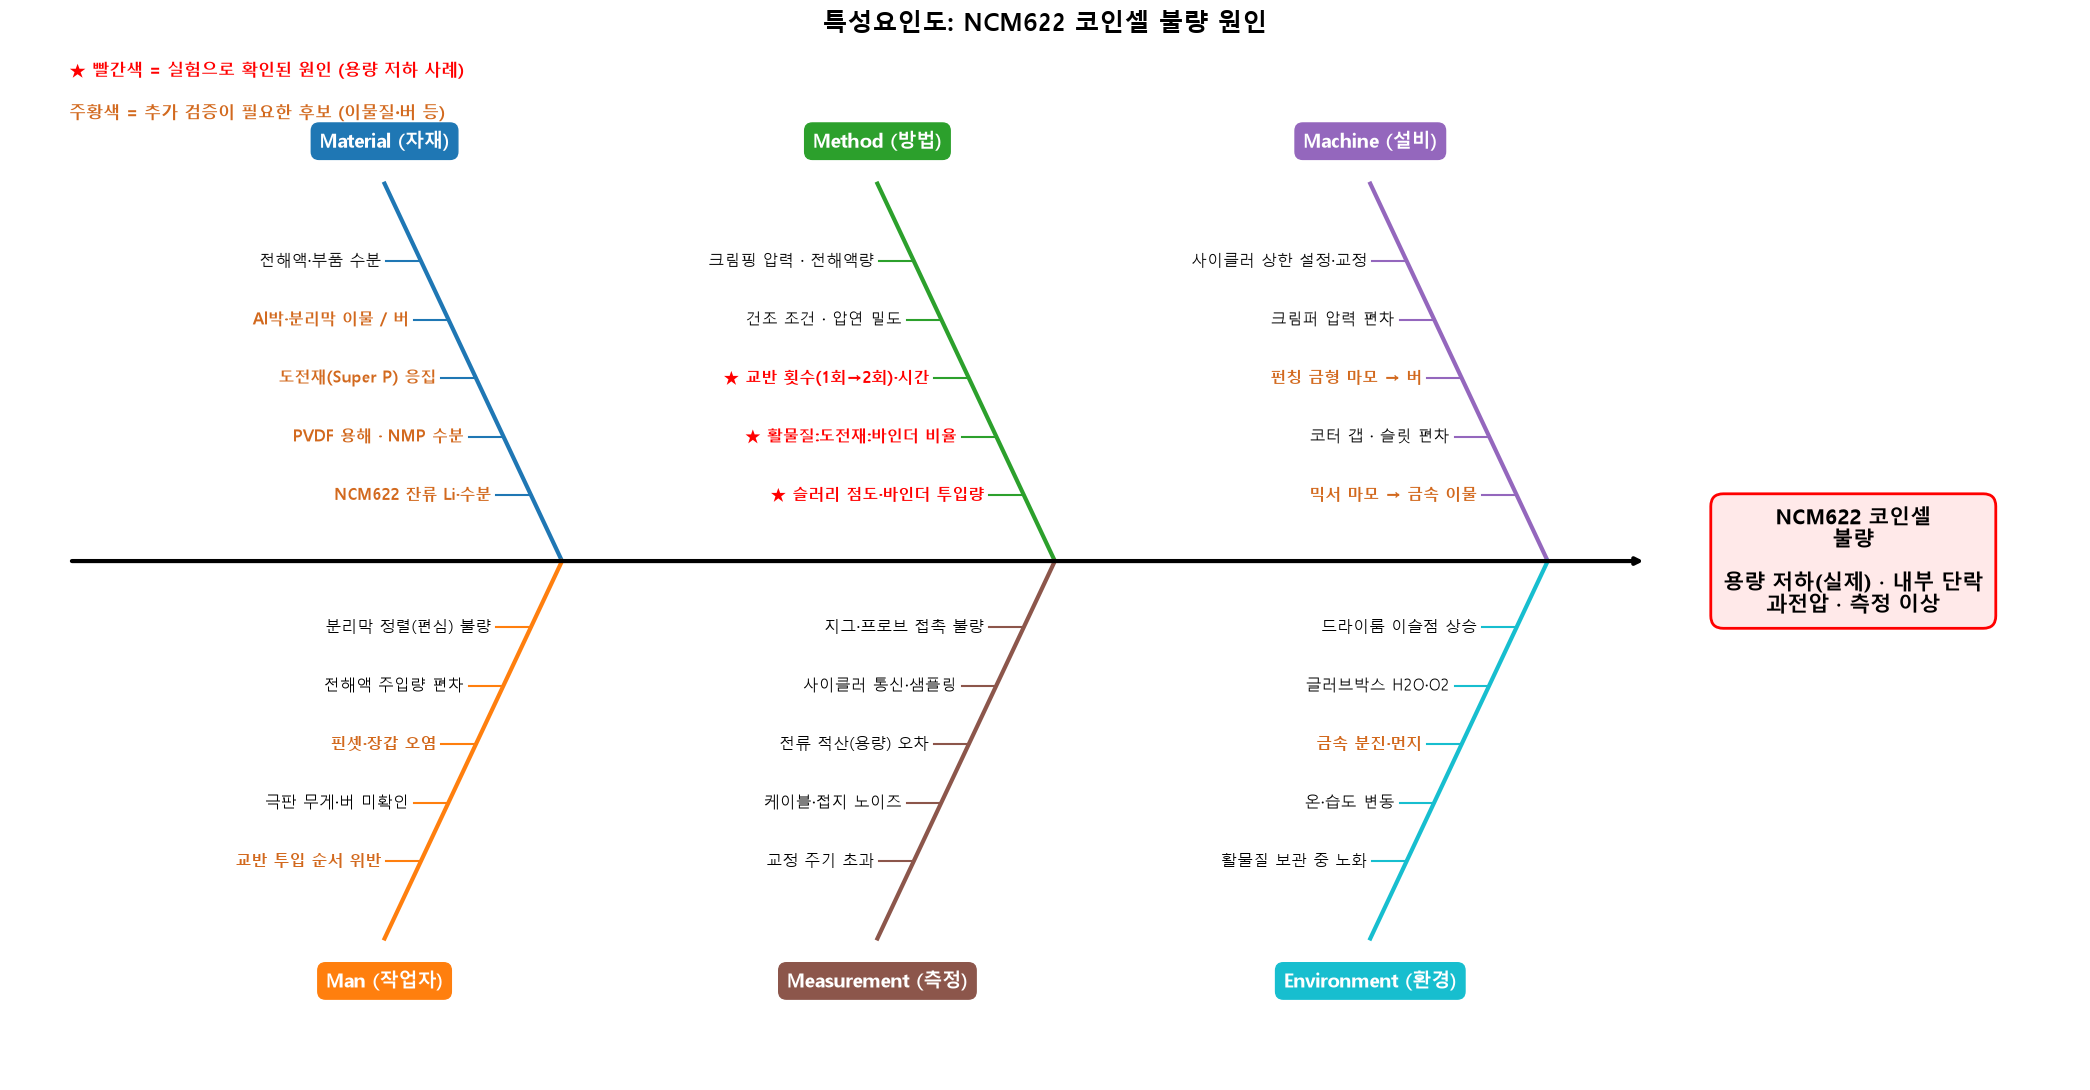

In [5]:
branches = {
    'Material (자재)': [('NCM622 잔류 Li·수분', 1), ('PVDF 용해 · NMP 수분', 1), ('도전재(Super P) 응집', 1),
                        ('Al박·분리막 이물 / 버', 1), ('전해액·부품 수분', 0)],
    'Method (방법)': [('★ 슬러리 점도·바인더 투입량', 2), ('★ 활물질:도전재:바인더 비율', 2), ('★ 교반 횟수(1회→2회)·시간', 2),
                      ('건조 조건 · 압연 밀도', 0), ('크림핑 압력 · 전해액량', 0)],
    'Machine (설비)': [('믹서 마모 → 금속 이물', 1), ('코터 갭 · 슬릿 편차', 0), ('펀칭 금형 마모 → 버', 1),
                       ('크림퍼 압력 편차', 0), ('사이클러 상한 설정·교정', 0)],
    'Man (작업자)': [('분리막 정렬(편심) 불량', 0), ('전해액 주입량 편차', 0), ('핀셋·장갑 오염', 1),
                     ('극판 무게·버 미확인', 0), ('교반 투입 순서 위반', 1)],
    'Measurement (측정)': [('지그·프로브 접촉 불량', 0), ('사이클러 통신·샘플링', 0), ('전류 적산(용량) 오차', 0),
                           ('케이블·접지 노이즈', 0), ('교정 주기 초과', 0)],
    'Environment (환경)': [('드라이룸 이슬점 상승', 0), ('글러브박스 H2O·O2', 0), ('금속 분진·먼지', 1),
                           ('온·습도 변동', 0), ('활물질 보관 중 노화', 0)],
}
colors = ['#1f77b4', '#2ca02c', '#9467bd', '#ff7f0e', '#8c564b', '#17becf']

fig, ax = plt.subplots(figsize=(21, 11))
ax.set_xlim(0, 21); ax.set_ylim(0, 11); ax.axis('off')
ys = 5.5
ax.annotate('', xy=(16.6, ys), xytext=(0.6, ys), arrowprops=dict(arrowstyle='-|>', lw=3, color='black'))
ax.text(18.7, ys, 'NCM622 코인셀\n불량\n\n용량 저하(실제) · 내부 단락\n과전압 · 측정 이상', ha='center', va='center', fontsize=15, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', fc='#ffe9e9', ec='red', lw=2))

xs_list = [5.6, 10.6, 15.6]           # 가지가 주축과 만나는 x
for i, ((name, items), c) in enumerate(zip(branches.items(), colors)):
    top = i < 3
    xs = xs_list[i % 3]
    sgn = 1 if top else -1
    x_end, y_end = xs - 1.8, ys + sgn * 4.0
    ax.plot([xs, x_end], [ys, y_end], color=c, lw=3)
    ax.text(x_end, y_end + sgn * 0.45, name, ha='center', va='center', fontsize=14, fontweight='bold', color='white',
            bbox=dict(boxstyle='round,pad=0.4', fc=c, ec=c))
    for j, (txt, key) in enumerate(items):
        yy = ys + sgn * (0.7 + j * 0.62)
        xb = xs + (x_end - xs) * (yy - ys) / (y_end - ys)
        ax.plot([xb - 0.35, xb], [yy, yy], color=c, lw=1.5)
        ax.text(xb - 0.4, yy, txt, ha='right', va='center', fontsize=11.5,
                color={2: 'red', 1: '#d2691e', 0: 'black'}[key], fontweight='bold' if key else 'normal')

ax.text(0.6, 10.7, '★ 빨간색 = 실험으로 확인된 원인 (용량 저하 사례)', fontsize=12, color='red', fontweight='bold', va='center')
ax.text(0.6, 10.25, '주황색 = 추가 검증이 필요한 후보 (이물질·버 등)', fontsize=12, color='#d2691e', fontweight='bold', va='center')
ax.set_title('특성요인도: NCM622 코인셀 불량 원인', fontsize=18, fontweight='bold', pad=8)
plt.tight_layout()
fig.savefig(IMG_DIR / '특성요인도.png', dpi=130)
plt.show()

## 4. 불량 유형 × 원인 연관도 (정성 평가)
2 = 주원인, 1 = 영향 가능, 0 = 관련 낮음. **문헌·공정 지식에 근거한 가설**이며, 다음 절의 실험으로 확인해야 합니다.

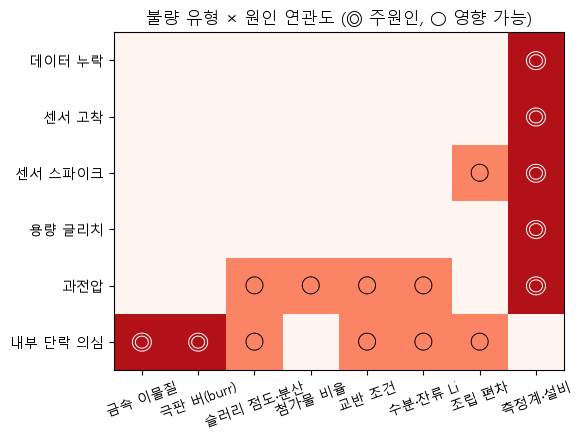

해석: 측정계 불량 4종은 '측정계·설비'로 수렴하고, 셀 불량인 내부 단락 의심은 이물질·버가 주원인, 슬러리·조립이 보조 원인입니다.


In [6]:
causes = ['금속 이물질', '극판 버(burr)', '슬러리 점도·분산', '첨가물 비율', '교반 조건', '수분·잔류 Li', '조립 편차', '측정계·설비']
M = pd.DataFrame([
    #            이물 버  점도 비율 교반 수분 조립 측정
    [0, 0, 0, 0, 0, 0, 0, 2],   # 데이터 누락
    [0, 0, 0, 0, 0, 0, 0, 2],   # 센서 고착
    [0, 0, 0, 0, 0, 0, 1, 2],   # 센서 스파이크
    [0, 0, 0, 0, 0, 0, 0, 2],   # 용량 글리치
    [0, 0, 1, 1, 1, 1, 0, 2],   # 과전압
    [2, 2, 1, 0, 1, 1, 1, 0],   # 내부 단락 의심
], index=['데이터 누락', '센서 고착', '센서 스파이크', '용량 글리치', '과전압', '내부 단락 의심'], columns=causes)

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(M.values, cmap='Reds', vmin=0, vmax=2.4)
ax.set_xticks(range(len(causes))); ax.set_xticklabels(causes, rotation=20)
ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        ax.text(j, i, {2: '◎', 1: '○', 0: ''}[v], ha='center', va='center', fontsize=16, color='white' if v == 2 else 'black')
ax.set_title('불량 유형 × 원인 연관도 (◎ 주원인, ○ 영향 가능)')
plt.tight_layout(); plt.show()
print("해석: 측정계 불량 4종은 '측정계·설비'로 수렴하고, 셀 불량인 내부 단락 의심은 이물질·버가 주원인, 슬러리·조립이 보조 원인입니다.")

## 5. 설계·공정 기록 점검 (실제 측정 파일)
`전지설계 기말과제1 부품규격.xlsx`의 **실제 측정값**으로 원인 가설을 점검합니다. 이상치 판정에는 앞서 쓴 것과 같은 로버스트 방식(중앙값·MAD)을 사용합니다.


■ 실제 측정값 점검 결과


,실측 결과,판정,의미
점검 항목,,,
분리막 두께 5회 측정,"0.0023, 0.026, 0.025, 0.027, 0.026 mm (수정 z: -16.0, 0.0, -0.7, 0.7, 0.0)",이상치,"0.0023 mm 하나가 나머지(약 0.026 mm)의 1/10 수준. 오타라면 평균·공차가 왜곡(0.0213±0.0106 → 제외 시 0.0260±0.0008), 실제 얇은 부위라면 단락 위험. 측정 원본 확인 필요"
분리막-양극 직경 여유,"분리막 14.01 mm, 양극 14.00 mm → 한쪽 여유 0.005 mm (측정 산포 0.042 mm)",위험,여유가 측정 산포보다 작아 조립 정렬이 조금만 틀어져도 양극 모서리가 분리막 밖으로 나가 음극과 닿을 수 있음 (내부 단락 후보 원인)
전극 두께 균일도 (CV),활물질+Cu: 9.7%→4.5%; 활물질+Al: 8.6%→2.4%; 활물질+Al(2): 4.6%→0.8%,주의,코팅 직후 산포가 크고 압연으로 줄어듦. 코팅(블레이드·점도)이 균일도에 영향
양극 질량 산포 (5명),"sample1 3.83 mg (CV 11.6%), sample2 8.24 mg (CV 2.5%)",주의,사람·세트 간 편차 존재. 측정 질량이 합제 기준인지 활물질 기준인지 확인 필요
충방전 데이터 출처 대조,"전류 0.2473 mA (0.2C 설계 0.2473 mA), 충전 1.197 mAh / 설계 1.237 mAh = 96.8%",일치,학생5 sample2 셀의 데이터로 보임. 컬럼명 'Ah/cm2'는 셀 전체 Ah로 추정


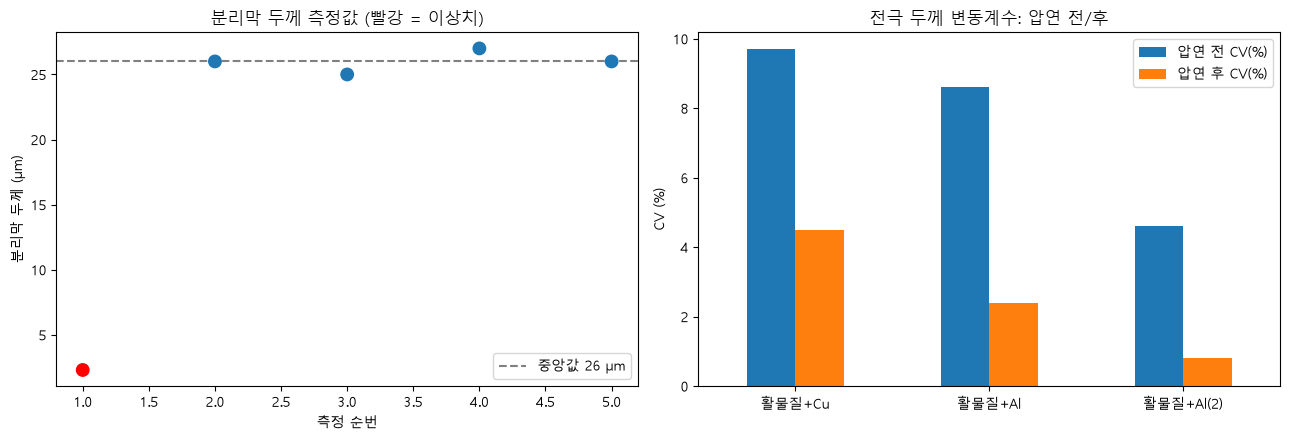

In [7]:
def mod_z(x):
    """수정 z-score (중앙값/MAD 기반, |z|>3.5이면 이상치)"""
    x = np.asarray(x, float)
    med = np.median(x)
    mad = 1.4826 * np.median(np.abs(x - med))
    return (x - med) / mad


parts = wb['부품측정후']
sep_t, sep_d = cells(parts, 'I2:I6'), cells(parts, 'H2:H6')       # 분리막 두께/직경 (mm)
cat_d, ano_d = cells(parts, 'E13:E17'), cells(parts, 'B13:B17')   # 양극/음극 직경 (mm)

# (1) 분리막 두께 이상치
z = mod_z(sep_t)
is_out = np.abs(z) > 3.5
keep = sep_t[~is_out]
# (2) 분리막-양극 직경 여유
margin_side = (sep_d.mean() - cat_d.mean()) / 2
spread = max(sep_d.std(ddof=1), cat_d.std(ddof=1))


# (3) 전극 두께 균일도
def thickness(sheet):
    ws = wb[sheet]
    return {n: cells(ws, f'{c}2:{c}6') for n, c in [('활물질+Cu', 'C'), ('활물질+Al', 'E'), ('활물질+Al(2)', 'G')]}


before, after = thickness('압연전'), thickness('압연후')
cv_tbl = pd.DataFrame({'압연 전 CV(%)': {k: cv(v) for k, v in before.items()},
                       '압연 후 CV(%)': {k: cv(v) for k, v in after.items()}}).round(1)
# (4) 양극 질량 산포
ws = wb['질량 및 용량, 전류']
names = [c.value for row in ws['A2:A6'] for c in row]
m1, m2 = cells(ws, 'B2:B6') * 1000, cells(ws, 'E2:E6')               # sample1 (g→mg), sample2 (mg)
# (5) 충방전 데이터와의 대조
Qc = pd.read_excel(CELL_FILE)['누적 용량_d(Ah/cm2)'].to_numpy()
imx = int(np.argmax(Qc))
i_mA = np.median(np.abs(np.diff(Qc))) * 3.6e6                         # Ah/초 → mA
k = names.index(OWNER)
cap_design = 145 * m2[k] * 1e-3                                         # 실용량 145 mAh/g × 양극 질량
cap_meas = (Qc[imx] - Qc[0]) * 1000

out_msg = '-'
if is_out.any():
    out_msg = (f"{sep_t[is_out][0]:g} mm 하나가 나머지(약 {np.median(keep):g} mm)의 1/10 수준. "
               f"오타라면 평균·공차가 왜곡({sep_t.mean():.4f}±{sep_t.std(ddof=1):.4f} → 제외 시 {keep.mean():.4f}±{keep.std(ddof=1):.4f}), "
               "실제 얇은 부위라면 단락 위험. 측정 원본 확인 필요")
summary = pd.DataFrame([
    ['분리막 두께 5회 측정', f"{', '.join(f'{v:g}' for v in sep_t)} mm  (수정 z: {', '.join(f'{v:.1f}' for v in z)})",
     '이상치' if is_out.any() else '정상', out_msg],
    ['분리막-양극 직경 여유', f"분리막 {sep_d.mean():.2f} mm, 양극 {cat_d.mean():.2f} mm → 한쪽 여유 {margin_side:.3f} mm (측정 산포 {spread:.3f} mm)",
     '위험' if margin_side < spread else '정상',
     '여유가 측정 산포보다 작아 조립 정렬이 조금만 틀어져도 양극 모서리가 분리막 밖으로 나가 음극과 닿을 수 있음 (내부 단락 후보 원인)'],
    ['전극 두께 균일도 (CV)', '; '.join(f"{n}: {cv_tbl.loc[n, '압연 전 CV(%)']}%→{cv_tbl.loc[n, '압연 후 CV(%)']}%" for n in cv_tbl.index),
     '주의', '코팅 직후 산포가 크고 압연으로 줄어듦. 코팅(블레이드·점도)이 균일도에 영향'],
    ['양극 질량 산포 (5명)', f"sample1 {m1.mean():.2f} mg (CV {cv(m1):.1f}%), sample2 {m2.mean():.2f} mg (CV {cv(m2):.1f}%)",
     '주의', '사람·세트 간 편차 존재. 측정 질량이 합제 기준인지 활물질 기준인지 확인 필요'],
    ['충방전 데이터 출처 대조', f"전류 {i_mA:.4f} mA (0.2C 설계 {0.2 * cap_design:.4f} mA), 충전 {cap_meas:.3f} mAh / 설계 {cap_design:.3f} mAh = {cap_meas / cap_design * 100:.1f}%",
     '일치', f"{OWNER} sample2 셀의 데이터로 보임. 컬럼명 'Ah/cm2'는 셀 전체 Ah로 추정"],
], columns=['점검 항목', '실측 결과', '판정', '의미'])
show(summary.set_index('점검 항목'), '실제 측정값 점검 결과')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.scatter(np.arange(1, 6), sep_t * 1000, c=np.where(is_out, 'red', 'tab:blue'), s=80, zorder=3)
ax.axhline(np.median(sep_t) * 1000, color='gray', ls='--', label=f'중앙값 {np.median(sep_t) * 1000:.0f} µm')
ax.set_xlabel('측정 순번'); ax.set_ylabel('분리막 두께 (µm)'); ax.set_title('분리막 두께 측정값 (빨강 = 이상치)'); ax.legend()
cv_tbl.plot.bar(ax=axes[1], rot=0); axes[1].set_ylabel('CV (%)'); axes[1].set_title('전극 두께 변동계수: 압연 전/후')
plt.tight_layout(); plt.show()

### 공정 조건 정리
작업자가 기억하는 **진술**과 **기록이 없는 값**을 구분해 적었습니다.

In [8]:
process = pd.DataFrame([
    ['교반 방식', '5분 교반 + 1분 휴지를 5번 반복 = 교반 1회 (휴지 포함 30분 안팎)', '작업자 진술'],
    ['교반 횟수', '불량 샘플1: 1회 → 개선 샘플2: 2회 (60분 안팎)', '작업자 진술'],
    ['교반 장비·rpm·투입 순서', '확인 안 됨', '기록 없음'],
    ['슬러리 점도', '수치 기록 없음 (해체 시 점도 차이가 극명했다는 관찰만 있음)', '작업자 진술'],
], columns=['항목', '값', '구분']).set_index('항목')
show(process, '공정 조건 정리')


■ 공정 조건 정리


,값,구분
항목,,
교반 방식,5분 교반 + 1분 휴지를 5번 반복 = 교반 1회 (휴지 포함 30분 안팎),작업자 진술
교반 횟수,불량 샘플1: 1회 → 개선 샘플2: 2회 (60분 안팎),작업자 진술
교반 장비·rpm·투입 순서,확인 안 됨,기록 없음
슬러리 점도,수치 기록 없음 (해체 시 점도 차이가 극명했다는 관찰만 있음),작업자 진술


## 6. 원인 검증 계획
### 6-1. 무엇을 측정해 확인할지

In [9]:
verify = pd.DataFrame([
    ['슬러리 점도', '회전 점도계(전단율별)', '로트별 점도 분포와 불량률의 관계', '점도가 규격 밖일 때 불량률이 높은가'],
    ['슬러리 겔화·수분', '육안/점도 경시 변화, 칼 피셔 수분 측정', '원료 로트별 수분·잔류 Li와 점도 변화', '수분·잔류 Li가 높을수록 점도가 불안정한가'],
    ['도전재 분산도', '그라인드 게이지·현미경', '응집체 크기 분포', '응집체가 클수록 내부 단락·저항이 높은가'],
    ['첨가물 비율', '배합 기록 + 내부저항(EIS)', '도전재:바인더 비율과 저항·과전압 관계', '비율 변화에 따라 저항·과전압이 달라지는가'],
    ['금속 이물질', '자석 포집량, SEM-EDS, ICP', '로트별 이물 포집량과 내부 단락 발생률', '이물이 많은 로트에서 단락이 많은가'],
    ['극판 버', '현미경으로 가장자리 버 높이 측정', '버 높이와 분리막 두께 비교', '버 높이가 분리막 두께에 근접한 극판에서 단락이 많은가'],
    ['조립 편차', '크림핑 압력·전해액량·정렬 기록', '조립 변수와 불량의 관계', '조립 변수 편차가 클수록 불량이 늘어나는가'],
    ['측정계', '지그 접촉저항, 사이클러 교정 이력', '측정 이상 발생 시점과 지그·교정 이력 대조', '교정 주기 초과·접점 노후 시 측정 이상이 늘어나는가'],
], columns=['검증 항목', '측정 방법', '확인할 것', '판정 질문'])
show(verify)

,검증 항목,측정 방법,확인할 것,판정 질문
0,슬러리 점도,회전 점도계(전단율별),로트별 점도 분포와 불량률의 관계,점도가 규격 밖일 때 불량률이 높은가
1,슬러리 겔화·수분,"육안/점도 경시 변화, 칼 피셔 수분 측정",원료 로트별 수분·잔류 Li와 점도 변화,수분·잔류 Li가 높을수록 점도가 불안정한가
2,도전재 분산도,그라인드 게이지·현미경,응집체 크기 분포,응집체가 클수록 내부 단락·저항이 높은가
3,첨가물 비율,배합 기록 + 내부저항(EIS),도전재:바인더 비율과 저항·과전압 관계,비율 변화에 따라 저항·과전압이 달라지는가
4,금속 이물질,"자석 포집량, SEM-EDS, ICP",로트별 이물 포집량과 내부 단락 발생률,이물이 많은 로트에서 단락이 많은가
5,극판 버,현미경으로 가장자리 버 높이 측정,버 높이와 분리막 두께 비교,버 높이가 분리막 두께에 근접한 극판에서 단락이 많은가
6,조립 편차,크림핑 압력·전해액량·정렬 기록,조립 변수와 불량의 관계,조립 변수 편차가 클수록 불량이 늘어나는가
7,측정계,"지그 접촉저항, 사이클러 교정 이력",측정 이상 발생 시점과 지그·교정 이력 대조,교정 주기 초과·접점 노후 시 측정 이상이 늘어나는가


### 6-2. 실험계획(DOE): 슬러리 조건이 불량에 미치는 영향
**점도 · 첨가물(바인더) 비율 · 교반 횟수(1회/2회)** 를 요인으로 하는 3×3×2 완전요인 설계입니다. 교반 1회 vs 2회는 이미 1개씩 확인한 조건이라, **반복 셀 수를 늘려 통계적으로 확증**하는 것이 목적입니다. 점도·비율 수준은 **저/중/고**로 적었으니 공정 규격에 맞춰 채우세요.
**반응변수**는 셀별 불량 여부로, `02_전처리_분석_문제해결.ipynb`의 탐지 알고리즘으로 자동 판정할 수 있습니다.

In [10]:
levels = dict(점도=['저', '중', '고'], 도전재_바인더_비율=['저', '중', '고'], 교반=['1회', '2회'])
doe = pd.DataFrame(list(itertools.product(*levels.values())), columns=list(levels.keys()))
doe.insert(0, '실험 번호', np.arange(1, len(doe) + 1))
doe['반복 셀 수'] = 5
doe['반응변수'] = '내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항'
print(f"총 {len(doe)}조건 × 반복 5셀 = {len(doe) * 5}셀 (난수 순서로 실행해 요인 외 영향을 분산)")
rng = np.random.default_rng(0)
doe['실행 순서'] = rng.permutation(len(doe)) + 1
show(doe.sort_values('실행 순서').reset_index(drop=True).head(8))
print("... (전체 18조건)")
print("\n분석 방법: 요인별 불량률 비교(카이제곱/로지스틱 회귀), 초기 용량·내부저항은 3원 분산분석(ANOVA)으로 주효과·교호작용 검정")

총 18조건 × 반복 5셀 = 90셀 (난수 순서로 실행해 요인 외 영향을 분산)


,실험 번호,점도,도전재_바인더_비율,교반,반복 셀 수,반응변수,실행 순서
0,5,저,고,1회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",1
1,17,고,고,1회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",2
2,1,저,저,1회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",3
3,3,저,중,1회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",4
4,6,저,고,2회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",5
5,8,중,저,2회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",6
6,13,고,저,1회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",7
7,7,중,저,1회,5,"내부 단락 의심 구간 유무, 과전압 발생, 초기 용량, 내부저항",8


... (전체 18조건)

분석 방법: 요인별 불량률 비교(카이제곱/로지스틱 회귀), 초기 용량·내부저항은 3원 분산분석(ANOVA)으로 주효과·교호작용 검정


## 7. 정리
| 구분 | 불량 | 주원인(가설) | 우선 조치 |
|---|---|---|---|
| 측정계 | 누락·고착·스파이크·용량 글리치 | 지그 접촉·케이블·통신 | 점검 주기 설정, 탐지·보정 알고리즘 상시 적용 |
| 설비 | 과전압 | 상한 설정·교정 편차 | 교정 주기 관리, 이중 보호 |
| 셀 | **용량 저하 (실제 사례)** | **슬러리 점도(바인더 과다 유입) + 교반 부족 — 실험으로 확인** | 바인더 투입 질량 확인, 교반 2회 표준화, 극판 질량 하한 검사 |
| 셀 | 내부 단락 의심 | 금속 이물·버, 슬러리 점도·분산, **분리막-양극 직경 여유 부족(실측)** | 이물 포집·금형 관리, 점도·교반 표준화, 분리막 직경 확대 검토 |

**한계**: 용량 저하의 원인은 실험으로 확인했지만 교반 1회·2회 각 1개 샘플의 비교이고 점도 수치는 없습니다. 불량 시나리오 6종의 원인은 문헌 기반 가설입니다. 코인셀은 조립 재현성이 낮아서(TU Berlin 연구에서는 흔히 중요하다고 알려진 조립 변수가 정상 셀 수에 유의한 영향을 주지 않았음) 다른 요인이 더 클 수 있으니, **6절의 측정·DOE로 우선순위를 확인**해야 합니다.

### 참고 문헌
1. Laurita et al., *Residual Li2O degrades PVdF during the preparation of NMC811 slurries*, Chem. Commun. 2023 — https://pubs.rsc.org/en/content/articlelanding/2023/cc/d3cc00471f
2. J. Mater. Chem. A 2026, d5ta07131c (PVDF 용액 점도에 따른 카본블랙 슬러리 구조) — https://pubs.rsc.org/en/content/articlehtml/2026/ta/d5ta07131c
3. Sigma-Aldrich, *Streamlined electrode fabrication: user-friendly guide for cathode electrodes* (NMC811:Super P:PVDF = 90:5:5) — https://www.sigmaaldrich.com/CA/en/technical-documents/protocol/materials-science-and-engineering/batteries-supercapacitors-and-fuel-cells/streamlined-electrode-fabrication-user-friendly-guide-cathode-electrodes
4. Volta Foundation, *Optimizing mixing processes for battery electrode slurries* — https://volta.foundation/optimizing-mixing-processes-for-battery-electrode-slurries/
5. PNNL, *Pave the way for large-scale electrode processing of moisture-sensitive Ni-rich cathodes* — https://www.pnnl.gov/publications/pave-way-large-scale-electrode-processing-moisture-sensitive-ni-rich-cathodes
6. Bi et al., J. Electrochem. Soc. 2022 (NMC811 슬러리 유변학과 건조 전극 특성, 겔화 대책) — https://data.pnnl.gov/group/nodes/publication/32885
7. KIT 공개 논문 (Fe·Cu·Al 금속 입자 오염과 내부 단락: 설비 마모, 절단 버, 취급 중 노출) — https://publikationen.bibliothek.kit.edu/1000194787/184211754
8. NREL 발표 자료 (제조 결함에 의한 잠재 내부 단락, 소비자용 1~10 ppm 수준) — https://nrel.gov/docs/fy11osti/50082.pdf
9. (4M 표의 이물질 항목은 [7], [8], 그리고 아래 [13]의 버 관련 내용을 함께 근거로 함)
10. Univ. of Kentucky thesis (고속 교반에 의한 바인더·도전재 응집층) — https://uknowledge.uky.edu/cme_etds/181
11. TU Berlin, *Reproducible Production of Lithium-Ion Coin Cells* — https://depositonce.tu-berlin.de/items/d04adb6a-0eb5-40b3-a2ad-92fdddd9033b/full
12. MDPI Energies 15(21), 7949 (2022), 코인셀 설계(면적비 1.12~1.15, 전해액량) — https://www.mdpi.com/1996-1073/15/21/7949
13. iEST, *Why is coin cell specific capacity inconsistent?* (버, 수분, 전해액량 등) — https://iestbattery.com/coin-cell-testing-specific-capacity-accuracy/
14. MTI, *Procedure for Preparing Cathode Electrode Slurry & Recipe* (PVDF를 먼저 용해, 분말은 2~3회 나눠 투입) — https://mtixtl.com/en-euea/blogs/battery-research-knowledge-base/procedure-for-preparing-cathode-electrode-slurry-recipe
15. Morelly et al., Batteries 2024 (NMC 슬러리의 점도·미세구조가 혼합 프로토콜에 의존, 고전단 혼합 시 콜로이드 겔 형성) — https://doaj.org/article/5384a02abbe744cb8872a020127321ad
16. IIT Jodhpur, 혼합·건조 조건이 전기화학 성능에 미치는 영향 (교반 시간 3~6 h 비교) — https://research.iitj.ac.in/pdf/publisher-pdf-fulltext-on-the-study-of-mixing-and-drying-on-electrochemical-performance